# Paskong Pinoy: A Visual Celebration of Christmas in the Philippines

A visual gallery of ten AI-generated scenes celebrating Filipino Christmas traditions, accompanied by the project cover artwork.

**Model:** `Efficient-Large-Model/Sana_1600M_1024px_diffusers`  
**Platform:** Nebius Serverless GPU  
**GPU:** NVIDIA L40S  
**Image configuration:** 1024 × 1024, 20 inference steps  
**Generated assets:** 10 PNG images

## Project cover

The cover artwork introduces the Filipino Christmas atmosphere that inspired this collection.

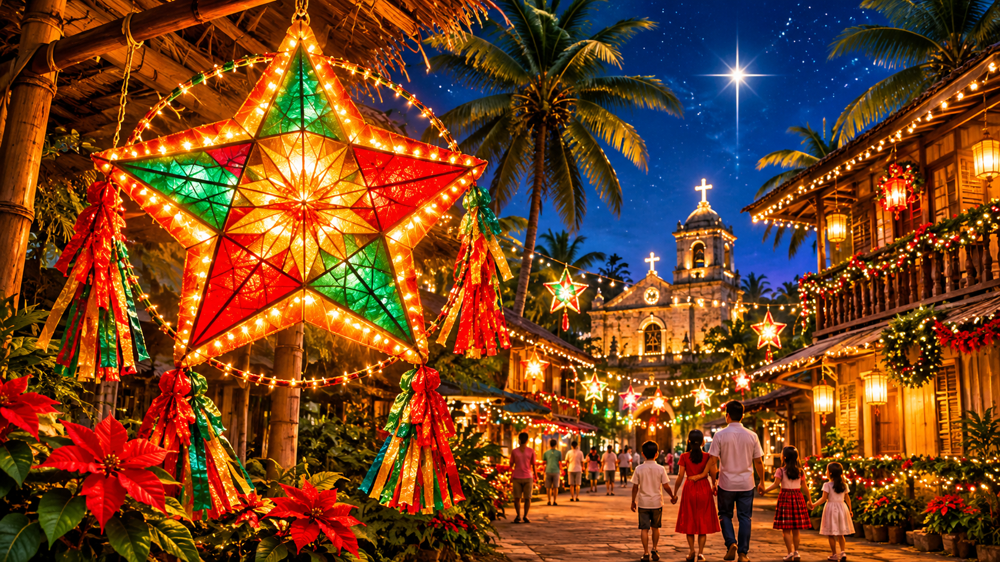

In [1]:
from pathlib import Path
import json
from IPython.display import display, Image, Markdown

# This notebook is designed to run from the repository root or its notebooks folder.
cwd = Path.cwd()
if (cwd / 'paskong-pinoy-module1').exists():
    project_dir = cwd / 'paskong-pinoy-module1'
elif cwd.name == 'notebooks' and cwd.parent.name == 'paskong-pinoy-module1':
    project_dir = cwd.parent
else:
    raise FileNotFoundError(
        'Could not locate paskong-pinoy-module1. Start Jupyter from the repository root '
        'or open this notebook from the project notebooks folder.'
    )

cover_path = project_dir / 'assets' / 'paskong-pinoy-cover.png'
if not cover_path.is_file():
    raise FileNotFoundError(f'Cover image not found: {cover_path}')

display(Image(filename=str(cover_path), width=1100))

## Generation run overview

In [2]:
run_id = 'paskong-pinoy-20261126T043156Z'
run_dir = project_dir / 'runs' / run_id
metrics_path = run_dir / 'metrics.json'

if not metrics_path.is_file():
    raise FileNotFoundError(f'Metrics file not found: {metrics_path}')

with metrics_path.open('r', encoding='utf-8') as f:
    metrics = json.load(f)

assets = metrics.get('assets', [])
successful = sum(a.get('status') == 'success' for a in assets)
display(Markdown(
    f"**Run ID:** `{metrics['run_id']}`  \n"
    f"**Status:** {metrics['status']}  \n"
    f"**Successful images:** {successful} / {len(assets)}  \n"
    f"**Failed images:** {len(metrics.get('errors', []))}  \n"
    f"**Total generation-loop time:** {metrics['total_generation_wall_s']:.2f} seconds"
))

**Run ID:** `paskong-pinoy-20261126T043156Z`  
**Status:** completed  
**Successful images:** 10 / 10  
**Failed images:** 0  
**Total generation-loop time:** 75.21 seconds

## The ten generated scenes

Each image is loaded from the original run directory. The notebook does not regenerate or modify any asset.

### 01. The Filipino Parol
**Seed:** `7` · **Replacement generation wall time: 11.93 s** · **File size:** `1.62 MB`

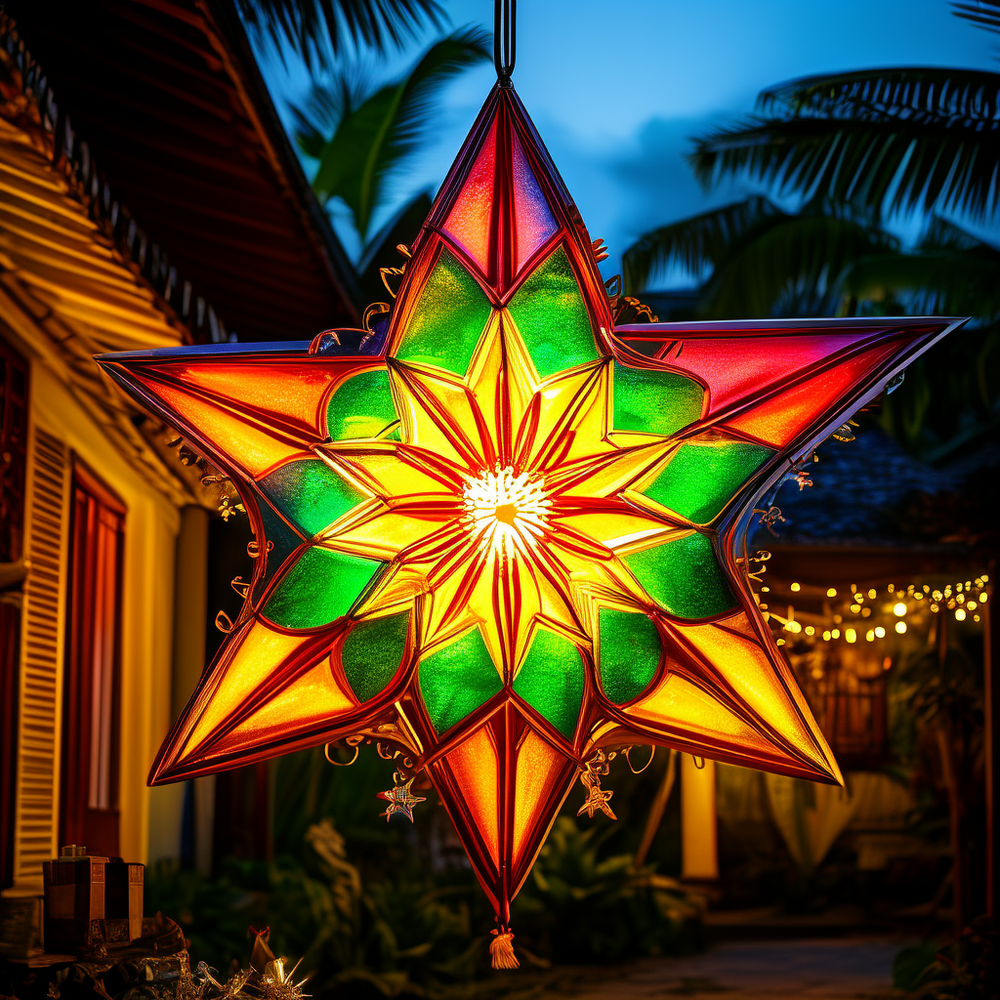

### 02. Paskong Barangay
**Seed:** `8` · **Generation time: 8.83 s** · **File size:** `1.78 MB`

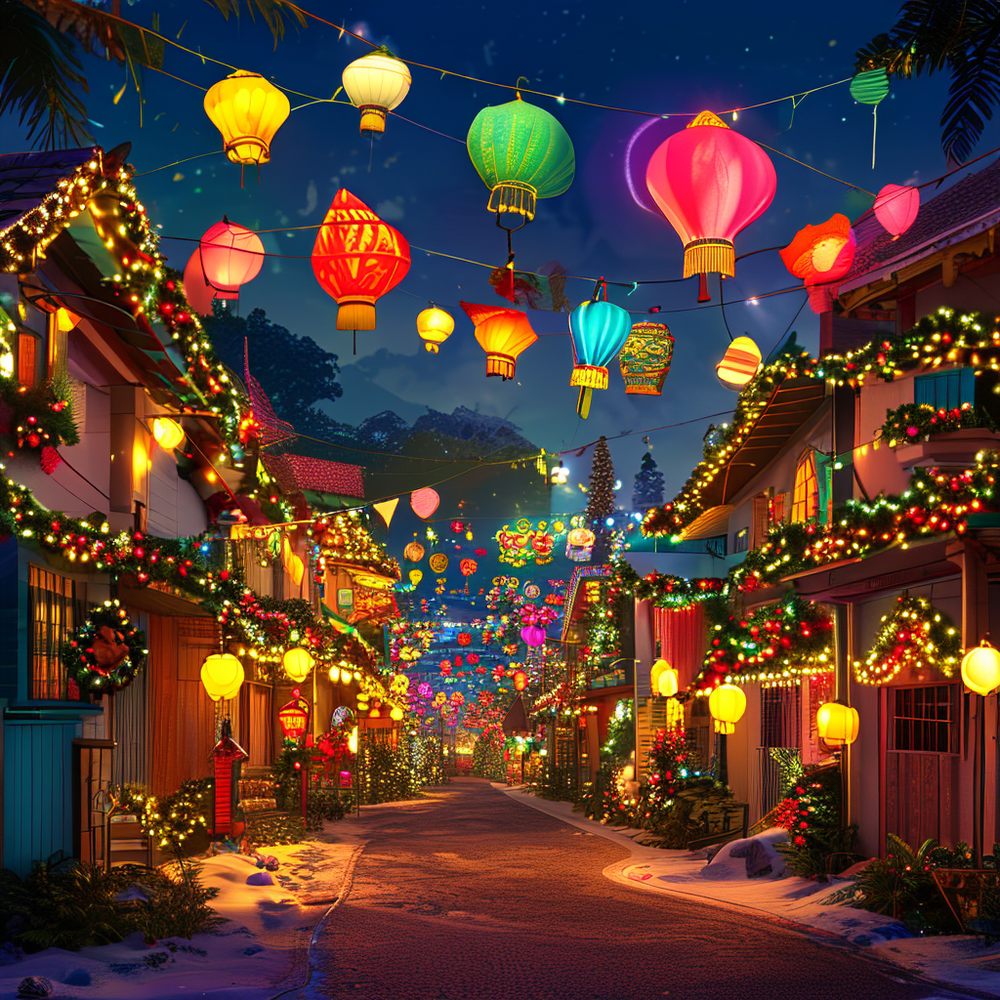

### 03. Simbang Gabi
**Seed:** `9` · **Generation time: 4.27 s** · **File size:** `1.74 MB`

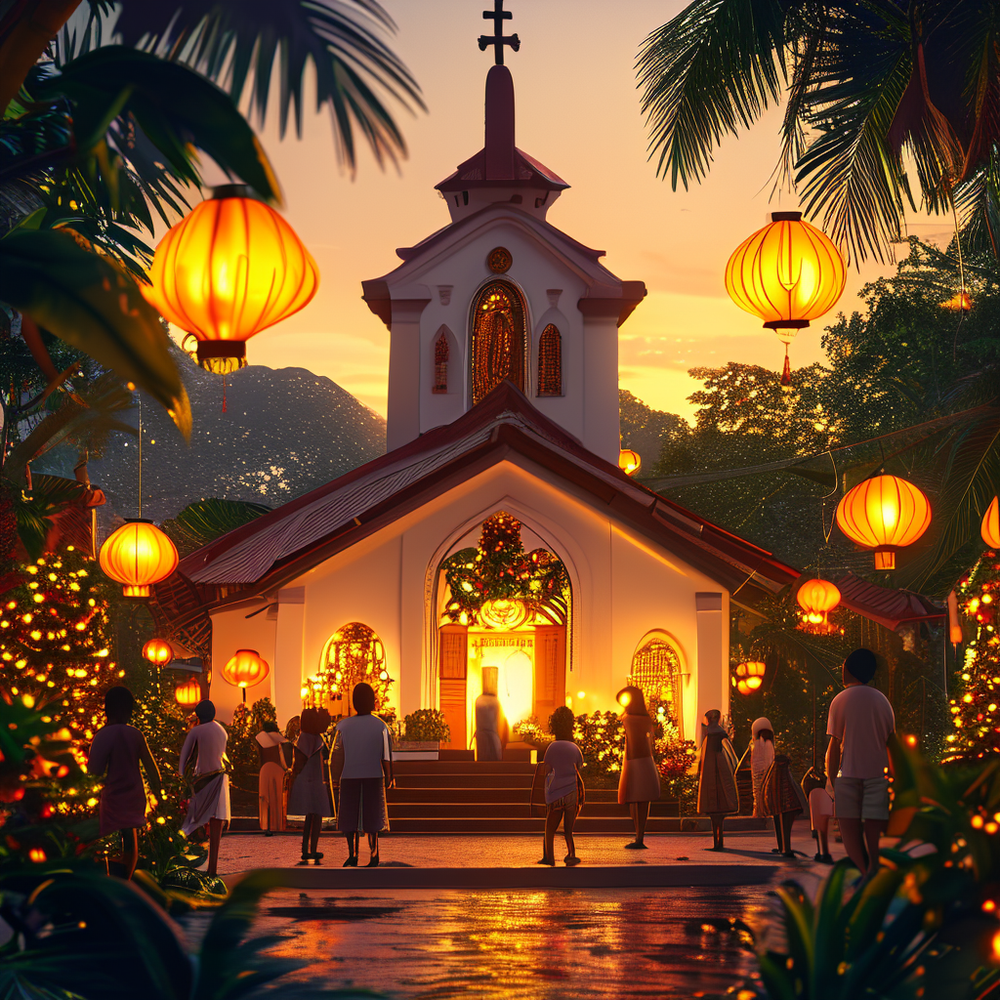

### 04. Noche Buena
**Seed:** `10` · **Generation time: 6.87 s** · **File size:** `1.44 MB`

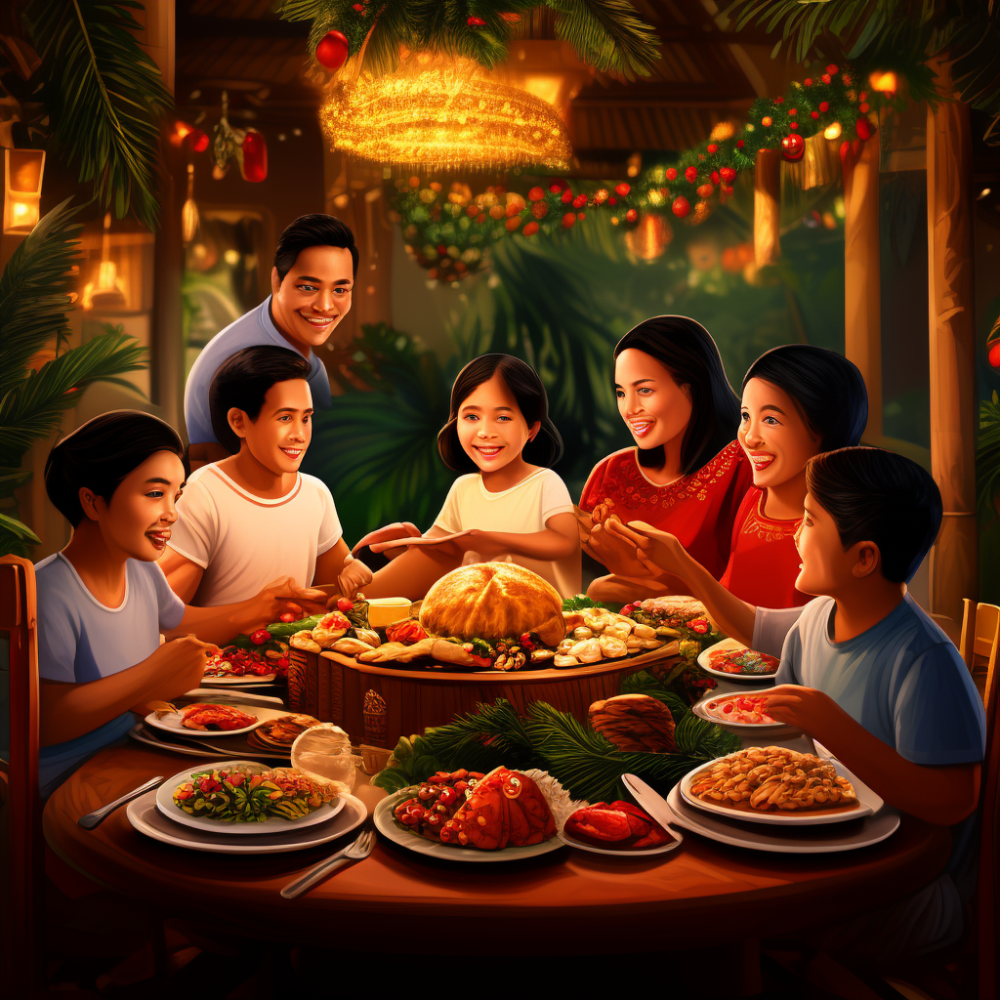

### 05. Filipino Christmas Delicacies
**Seed:** `11` · **Generation time: 9.53 s** · **File size:** `1.34 MB`

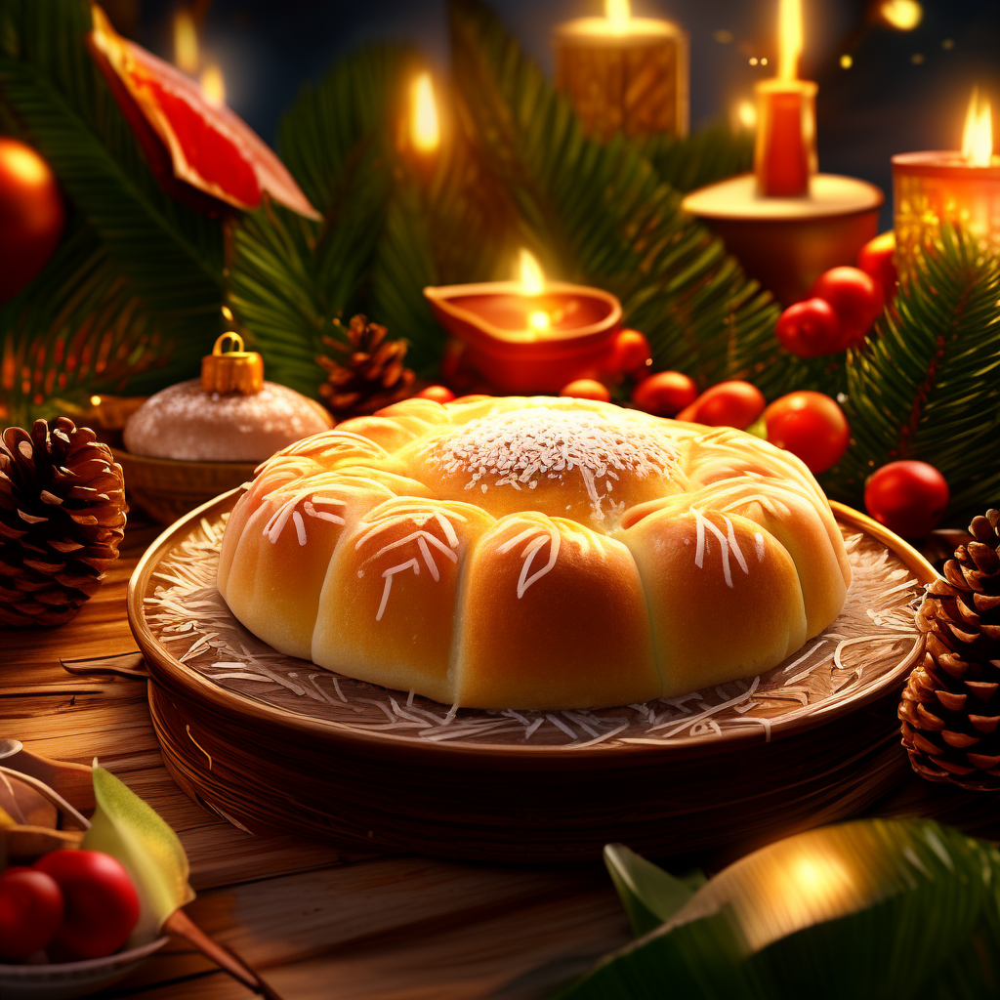

### 06. Giant Lantern Festival
**Seed:** `12` · **Generation time: 9.81 s** · **File size:** `1.78 MB`

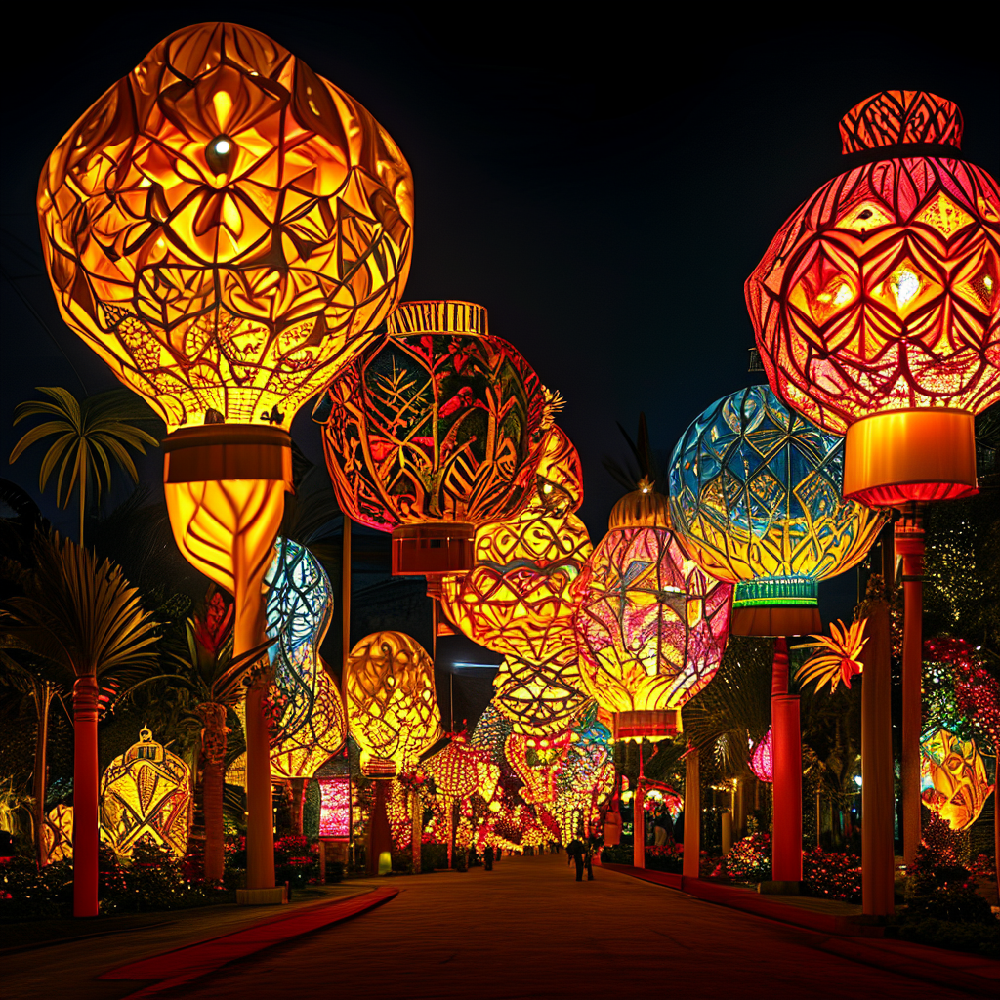

### 07. Family Christmas Preparations
**Seed:** `13` · **Generation time: 4.54 s** · **File size:** `1.48 MB`

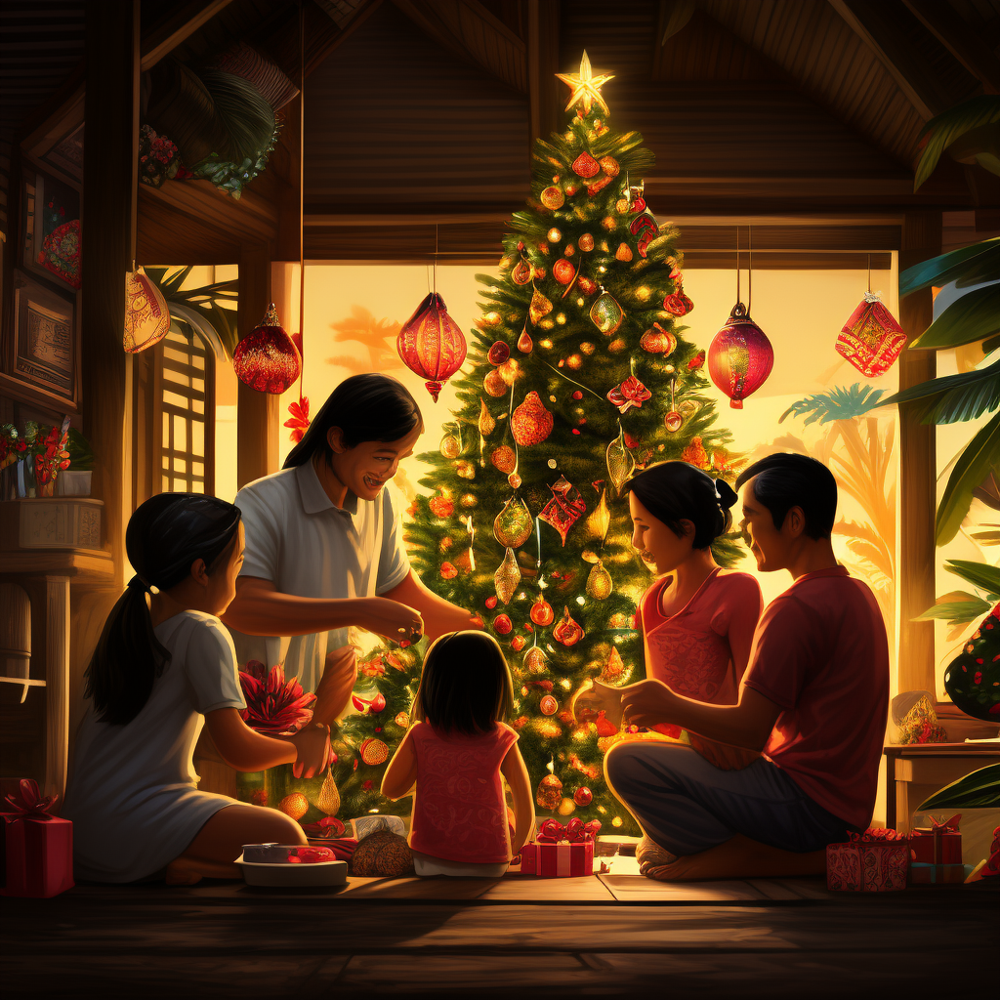

### 08. Christmas Caroling
**Seed:** `14` · **Generation time: 9.60 s** · **File size:** `1.33 MB`

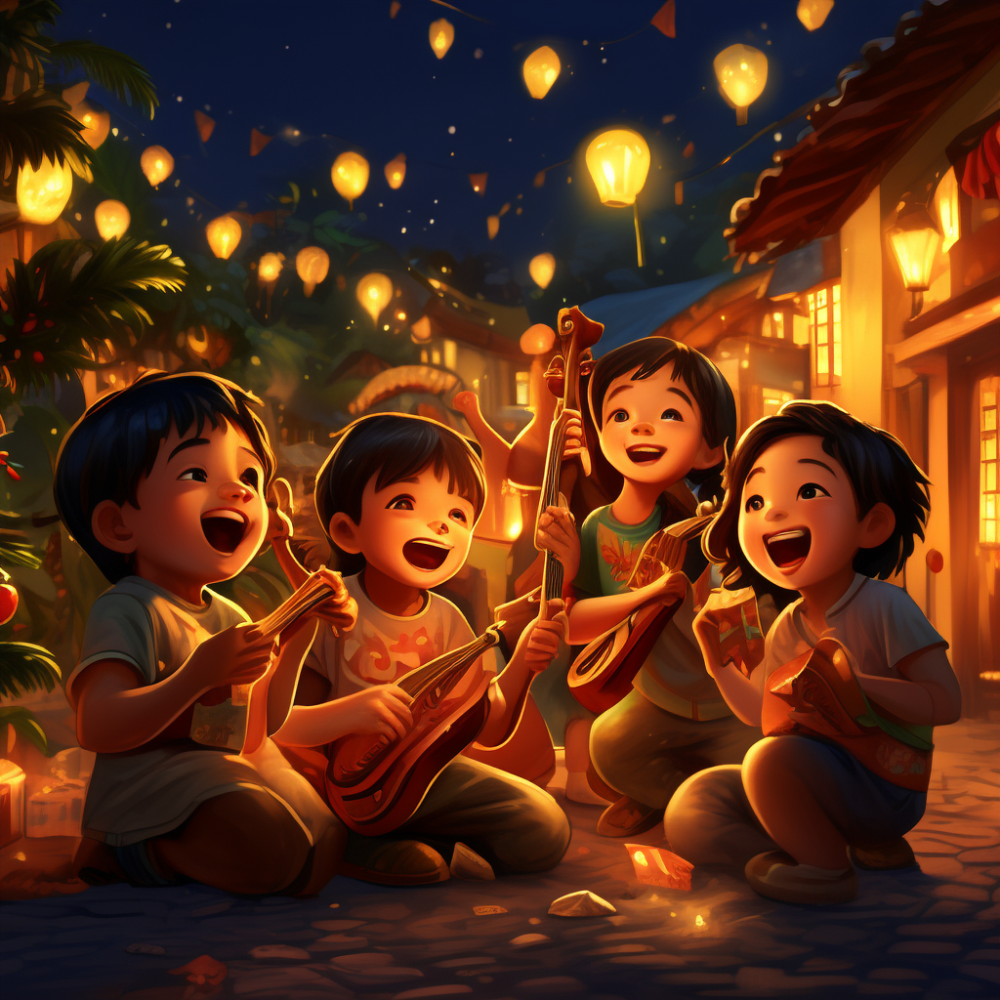

### 09. The Joy of Giving
**Seed:** `15` · **Generation time: 4.33 s** · **File size:** `1.39 MB`

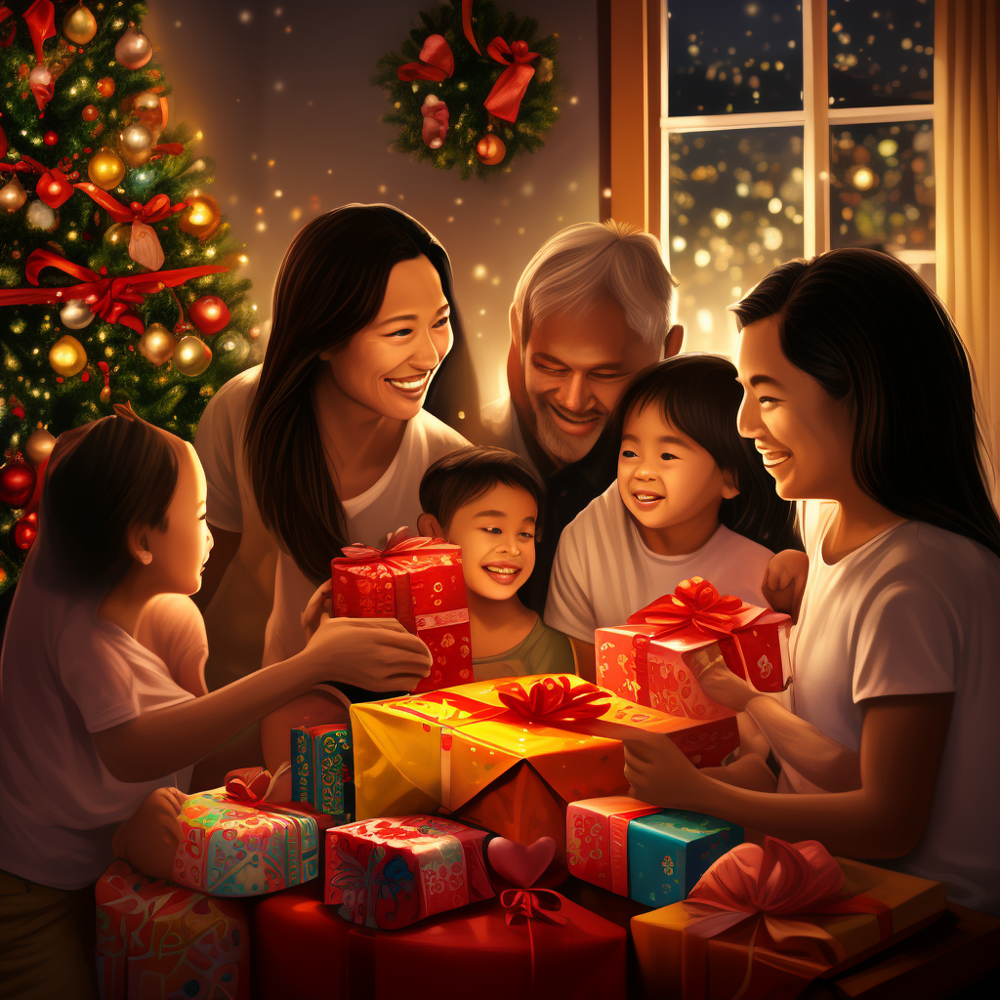

### 10. A Filipino Christmas Night
**Seed:** `16` · **Generation time: 9.66 s** · **File size:** `1.88 MB`

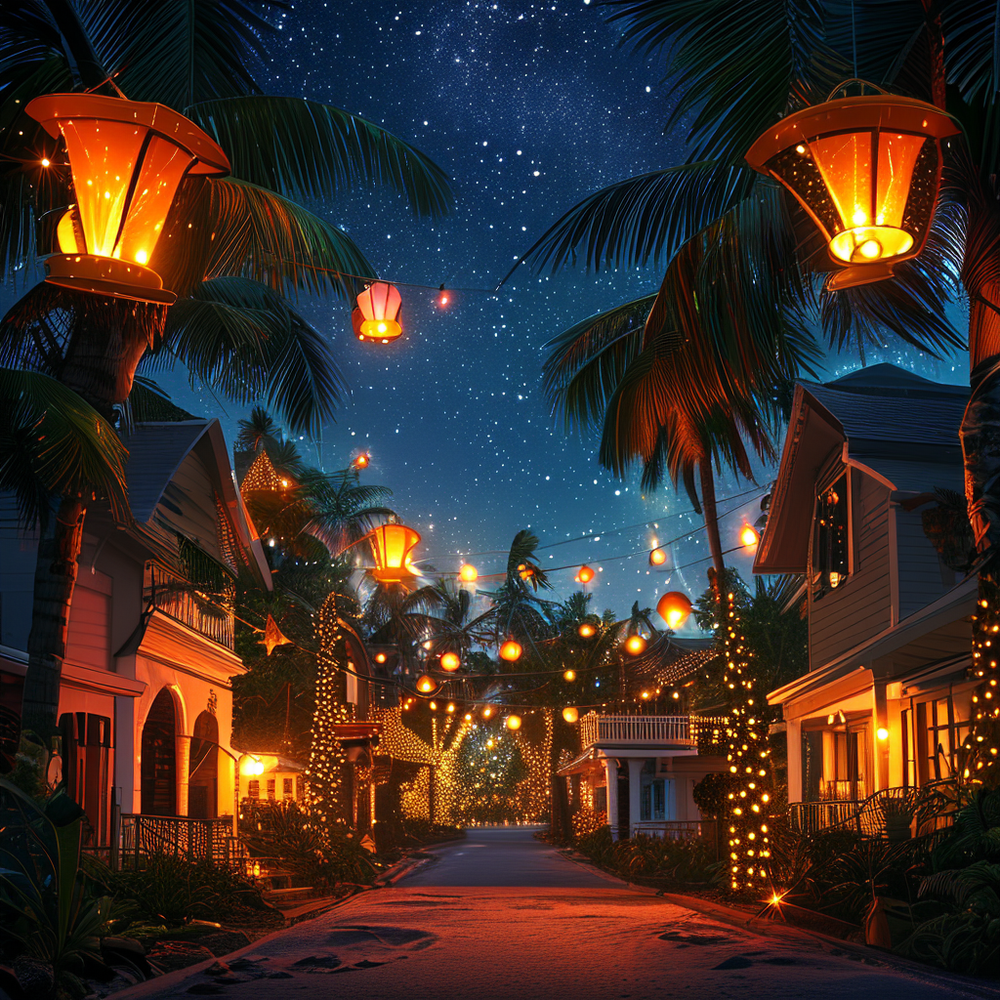

In [6]:
from IPython.display import display, Image, Markdown

for asset in assets:
    image_path = run_dir / asset['file']

    if not image_path.is_file():
        display(Markdown(
            f"### {asset['id']:02d}. {asset['title']}\n\n"
            f"**Missing file:** `{image_path}`"
        ))
        continue

    actual_size_mb = image_path.stat().st_size / (1024 * 1024)

    if asset['id'] == 1:
        generation_info = "Replacement generation wall time: 11.93 s"
    else:
        generation_info = (
            f"Generation time: {asset['api_latency_s']:.2f} s"
        )

    display(Markdown(
        f"### {asset['id']:02d}. {asset['title']}\n"
        f"**Seed:** `{asset['seed']}` · "
        f"**{generation_info}** · "
        f"**File size:** `{actual_size_mb:.2f} MB`"
    ))

    display(Image(filename=str(image_path), width=760))

## Cost and performance summary

In [5]:
import statistics

latencies = metrics.get('latency_s', [])
cost = metrics.get('cost_analysis', {}).get('calculation', {})
rate = metrics.get('cost_analysis', {}).get('gpu_rate_usd_per_hour')

if latencies:
    median_latency = statistics.median(latencies)
    print(f'Median image-generation latency: {median_latency:.3f} seconds')
if rate is not None:
    print(f'GPU rate used in estimate: ${rate:.2f} per hour')
if cost:
    print(f"Fixed run cost: ${cost['fixed_run_usd']:.6f}")
    print(f"Marginal compute cost per image: ${cost['marginal_compute_usd']:.6f}")
    print(f"Projected compute cost per image at 1,000 assets: ${cost['projected_compute_usd_per_asset']['1000']:.6f}")

print("\nNote: These are the recorded project estimates. Verify the provider's actual billable interval separately.")

Median image-generation latency: 8.226 seconds
GPU rate used in estimate: $0.65 per hour
Fixed run cost: $0.062978
Marginal compute cost per image: $0.001485
Projected compute cost per image at 1,000 assets: $0.001548

Note: These are the recorded project estimates. Verify the provider's actual billable interval separately.


## Closing note

Paskong Pinoy brings together Filipino Christmas imagery—from the parol and barangay celebrations to Simbang Gabi, Noche Buena, caroling, and the warmth of family. This gallery documents the ten outputs from one completed serverless image-generation run.